
# Classical NLP Models - Sentiment Analysis

## Project Objective
Build baseline machine learning models for sentiment classification.

## Models
1. Multinomial Naive Bayes
2. Logistic Regression

## Feature Extraction
- TF-IDF
- Unigrams
- Unigrams + Bigrams

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

## Dataset
- Training Set
- Validation Set
- Test Set

### 1. Import Libraries

In [1]:
# Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


### 2. Load Dataset

In [2]:
# Define project paths

DATA_DIR = Path("data/processed/splits")
RESULTS_DIR = Path("results")

# Create results folder automatically

RESULTS_DIR.mkdir(exist_ok=True)

# Load datasets

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# Display dataset shapes

print("Training Data:", train_df.shape)
print("Validation Data:", val_df.shape)
print("Testing Data:", test_df.shape)

# Display first rows

display(train_df.head())

Training Data: (90000, 6)
Validation Data: (13500, 6)
Testing Data: (13500, 6)


,text,label,language,source,domain,cleaned_text
0,سيستم سيء جدا جدا تم حظري بسبب استخدام برومو ك...,negative,ar,https://www.kaggle.com/datasets/fahdseddik/ara...,company reviews,سيستم سيء جدا جدا تم حظري بسبب استخدام برومو ك...
1,"First time here for me, third time for my guy....",neutral,en,https://huggingface.co/datasets/Yelp/yelp_revi...,places reviews,"first time here for me, third time for my guy...."
2,晕。。。收到的书是这样的。。。。这像是价格156元的正版原版书吗？!刚亚马逊快递员已经取走，...,negative,zh,https://huggingface.co/datasets/tyqiangz/multi...,tweets,"晕..收到的书是这样的..这像是价格156元的正版原版书吗?!刚亚马逊快递员已经取走,但却说..."
3,مصر كلها عيد ميلادها النهاردا 😂كل سنة و انتوا ...,positive,ar,https://www.kaggle.com/competitions/arabic-sen...,tweets,مصر كلها عيد ميلادها النهاردا 😂كل سنة و انتوا ...
4,عمل روائي يضج بالشخصيات المثيرة ... الغريبة ال...,positive,ar,https://www.kaggle.com/datasets/abedkhooli/ara...,"reviews (hotels, books, movies, products and a...",عمل روائي يضج بالشخصيات المثيرة .. الغريبة الت...


### 3. Prepare Text and Labels

In [3]:
# Check required columns

required_columns = {"cleaned_text", "label"}

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} dataset is missing columns: {missing}"
        )

# Handle missing text values

X_train = train_df["cleaned_text"].fillna("").astype(str)
y_train = train_df["label"].astype(str)

X_val = val_df["cleaned_text"].fillna("").astype(str)
y_val = val_df["label"].astype(str)

X_test = test_df["cleaned_text"].fillna("").astype(str)
y_test = test_df["label"].astype(str)

# Define sentiment classes

labels = ["negative", "neutral", "positive"]

# Check class distribution

print("Training Labels Distribution:")
print(y_train.value_counts())

print("\nValidation Labels Distribution:")
print(y_val.value_counts())

print("\nTest Labels Distribution:")
print(y_test.value_counts())

# Check unexpected labels

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    unexpected = set(y.unique()) - set(labels)

    if unexpected:
        raise ValueError(
            f"Unexpected labels in {name}: {unexpected}"
        )

print("\nData prepared successfully!")

Training Labels Distribution:
label
negative    30000
neutral     30000
positive    30000
Name: count, dtype: int64

Validation Labels Distribution:
label
positive    4500
negative    4500
neutral     4500
Name: count, dtype: int64

Test Labels Distribution:
label
positive    4500
negative    4500
neutral     4500
Name: count, dtype: int64

Data prepared successfully!


### 4. Tokenization and TF-IDF

In [4]:
# Define N-gram configurations

ngram_settings = {
    "Unigrams": (1, 1),
    "Unigrams + Bigrams": (1, 2)
}

print("N-gram configurations:")

for name, value in ngram_settings.items():
    print(f"{name}: {value}")

N-gram configurations:
Unigrams: (1, 1)
Unigrams + Bigrams: (1, 2)


### 5. Train Baseline Models and Evaluate


N-GRAM CONFIGURATION: Unigrams
Training features shape: (90000, 50000)
Validation features shape: (13500, 50000)
Testing features shape: (13500, 50000)

Training: Naive Bayes

Naive Bayes - Unigrams

Test Classification Report:
              precision    recall  f1-score   support

    negative     0.5085    0.8009    0.6221      4500
     neutral     0.6310    0.4538    0.5279      4500
    positive     0.7419    0.5238    0.6140      4500

    accuracy                         0.5928     13500
   macro avg     0.6272    0.5928    0.5880     13500
weighted avg     0.6272    0.5928    0.5880     13500



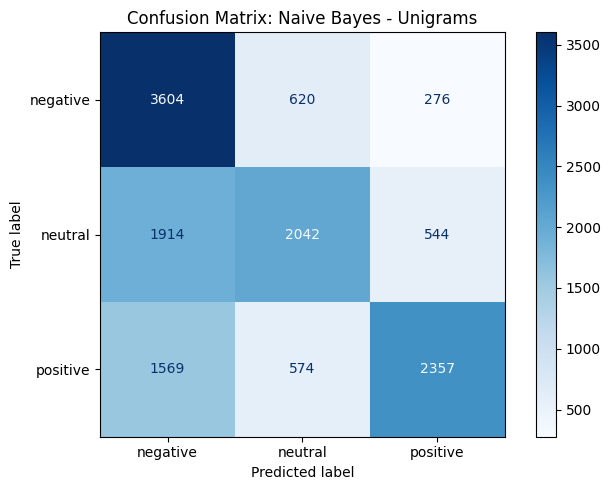


Training: Logistic Regression

Logistic Regression - Unigrams

Test Classification Report:
              precision    recall  f1-score   support

    negative     0.6981    0.5658    0.6250      4500
     neutral     0.5195    0.7207    0.6037      4500
    positive     0.7230    0.5800    0.6436      4500

    accuracy                         0.6221     13500
   macro avg     0.6469    0.6221    0.6241     13500
weighted avg     0.6469    0.6221    0.6241     13500



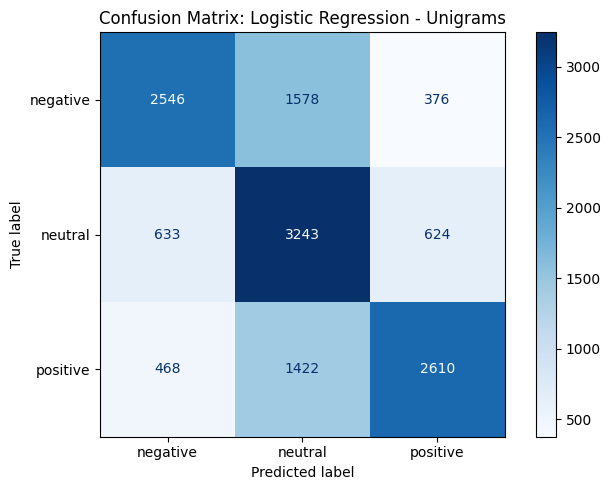


N-GRAM CONFIGURATION: Unigrams + Bigrams
Training features shape: (90000, 50000)
Validation features shape: (13500, 50000)
Testing features shape: (13500, 50000)

Training: Naive Bayes

Naive Bayes - Unigrams + Bigrams

Test Classification Report:
              precision    recall  f1-score   support

    negative     0.5049    0.7829    0.6139      4500
     neutral     0.6096    0.4684    0.5298      4500
    positive     0.7376    0.5022    0.5976      4500

    accuracy                         0.5845     13500
   macro avg     0.6174    0.5845    0.5804     13500
weighted avg     0.6174    0.5845    0.5804     13500



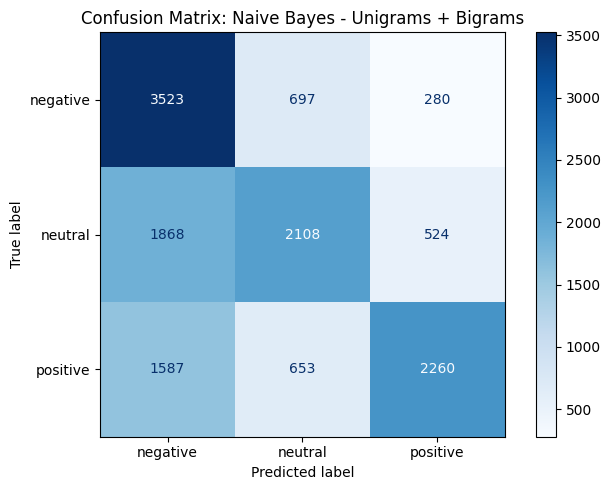


Training: Logistic Regression

Logistic Regression - Unigrams + Bigrams

Test Classification Report:
              precision    recall  f1-score   support

    negative     0.6967    0.5416    0.6094      4500
     neutral     0.5024    0.7353    0.5969      4500
    positive     0.7186    0.5453    0.6201      4500

    accuracy                         0.6074     13500
   macro avg     0.6392    0.6074    0.6088     13500
weighted avg     0.6392    0.6074    0.6088     13500



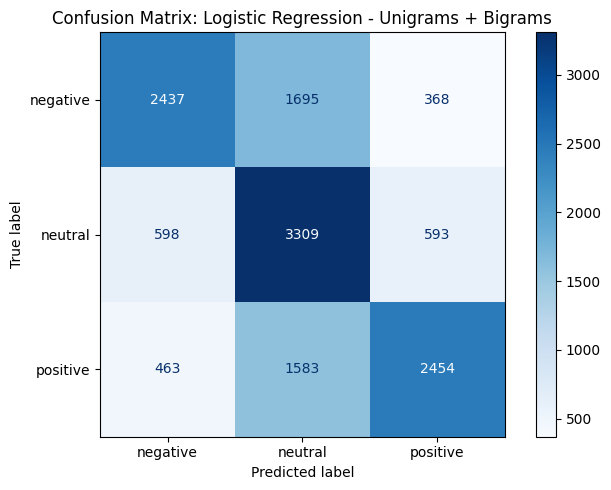


All four experiments completed successfully!


In [5]:

# Store evaluation results

validation_results = []
test_results = []

# Define model constructors

model_factories = {
    "Naive Bayes": lambda: MultinomialNB(),
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=1000
    )
}

# Run all experiments

for ngram_name, ngram_range in ngram_settings.items():

    print("\n" + "=" * 60)
    print(f"N-GRAM CONFIGURATION: {ngram_name}")
    print("=" * 60)

    # TF-IDF Vectorization

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=50000,
        sublinear_tf=True
    )

    # Fit vocabulary and IDF on training data only

    X_train_tfidf = vectorizer.fit_transform(X_train)

    # Transform validation and test data

    X_val_tfidf = vectorizer.transform(X_val)
    X_test_tfidf = vectorizer.transform(X_test)

    print("Training features shape:", X_train_tfidf.shape)
    print("Validation features shape:", X_val_tfidf.shape)
    print("Testing features shape:", X_test_tfidf.shape)

    # Train both models

    for model_name, create_model in model_factories.items():

        print(f"\nTraining: {model_name}")

        model = create_model()
        model.fit(X_train_tfidf, y_train)

        # ==================================
        # Validation Evaluation
        # ==================================

        val_pred = model.predict(X_val_tfidf)

        val_metrics = {
            "Model": model_name,
            "N-grams": ngram_name,
            "Accuracy": accuracy_score(y_val, val_pred),
            "Precision": precision_score(
                y_val, val_pred,
                labels=labels,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_val, val_pred,
                labels=labels,
                average="macro",
                zero_division=0
            ),
            "F1-score": f1_score(
                y_val, val_pred,
                labels=labels,
                average="macro",
                zero_division=0
            )
        }

        validation_results.append(val_metrics)

        # ==================================
        # Test Evaluation
        # ==================================

        test_pred = model.predict(X_test_tfidf)

        test_metrics = {
            "Model": model_name,
            "N-grams": ngram_name,
            "Accuracy": accuracy_score(y_test, test_pred),
            "Precision": precision_score(
                y_test, test_pred,
                labels=labels,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test, test_pred,
                labels=labels,
                average="macro",
                zero_division=0
            ),
            "F1-score": f1_score(
                y_test, test_pred,
                labels=labels,
                average="macro",
                zero_division=0
            )
        }

        test_results.append(test_metrics)

        print(f"\n{model_name} - {ngram_name}")
        print("\nTest Classification Report:")

        print(classification_report(
            y_test,
            test_pred,
            labels=labels,
            digits=4,
            zero_division=0
        ))

        # ==================================
        # Save Classification Report
        # ==================================

        report = classification_report(
            y_test,
            test_pred,
            labels=labels,
            digits=4,
            zero_division=0
        )

        safe_model_name = model_name.replace(" ", "_")
        safe_ngram_name = ngram_name.replace(" ", "_").replace("+", "plus")

        report_path = (
            RESULTS_DIR /
            f"report_{safe_model_name}_{safe_ngram_name}.txt"
        )

        with open(report_path, "w", encoding="utf-8") as file:
            file.write(report)

        # ==================================
        # Confusion Matrix
        # ==================================

        cm = confusion_matrix(
            y_test,
            test_pred,
            labels=labels
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=labels
        )

        fig, ax = plt.subplots(figsize=(7, 5))

        disp.plot(
            cmap="Blues",
            values_format="d",
            ax=ax
        )

        ax.set_title(
            f"Confusion Matrix: {model_name} - {ngram_name}"
        )

        plt.tight_layout()

        cm_path = (
            RESULTS_DIR /
            f"confusion_matrix_{safe_model_name}_{safe_ngram_name}.png"
        )

        plt.savefig(cm_path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

print("\nAll four experiments completed successfully!")


### 6. Compare Models

In [6]:
# Convert results into DataFrames

validation_results_df = pd.DataFrame(validation_results)
test_results_df = pd.DataFrame(test_results)

# Display validation comparison

print("VALIDATION SET COMPARISON")

display(
    validation_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

# Display final test comparison

print("TEST SET COMPARISON")

display(
    test_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

# Save comparison tables

validation_results_df.to_csv(
    RESULTS_DIR / "validation_comparison.csv",
    index=False
)

test_results_df.to_csv(
    RESULTS_DIR / "test_comparison.csv",
    index=False
)

print("Comparison tables saved successfully!")

VALIDATION SET COMPARISON


,Model,N-grams,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,Unigrams,0.5899,0.6225,0.5899,0.5847
1,Logistic Regression,Unigrams,0.6166,0.6410,0.6166,0.6184
2,Naive Bayes,Unigrams + Bigrams,0.5790,0.6114,0.5790,0.5748
3,Logistic Regression,Unigrams + Bigrams,0.6058,0.6385,0.6058,0.6077


TEST SET COMPARISON


,Model,N-grams,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,Unigrams,0.5928,0.6272,0.5928,0.5880
1,Logistic Regression,Unigrams,0.6221,0.6469,0.6221,0.6241
2,Naive Bayes,Unigrams + Bigrams,0.5845,0.6174,0.5845,0.5804
3,Logistic Regression,Unigrams + Bigrams,0.6074,0.6392,0.6074,0.6088


Comparison tables saved successfully!


### 7. Visualize Model Comparison

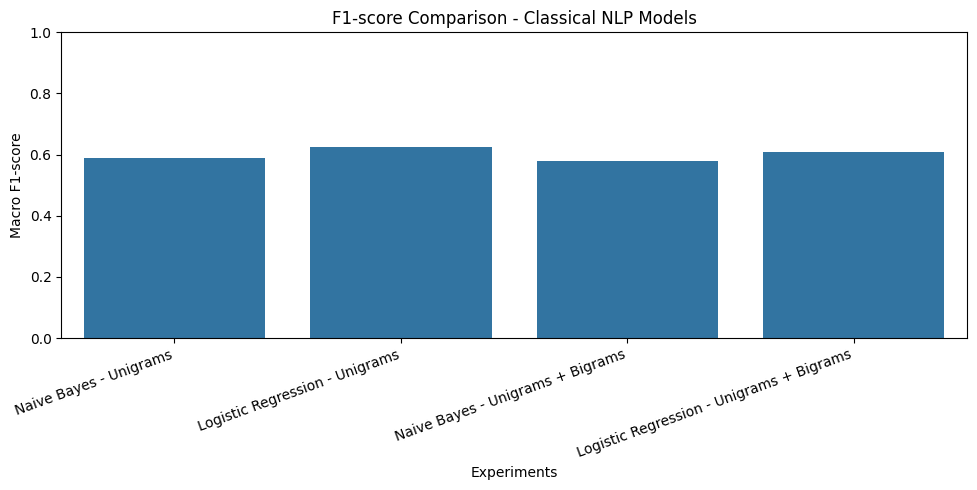

In [7]:
# Plot F1-score comparison on Test Set

plt.figure(figsize=(10, 5))

test_results_df["Experiment"] = (
    test_results_df["Model"] +
    " - " +
    test_results_df["N-grams"]
)

sns.barplot(
    data=test_results_df,
    x="Experiment",
    y="F1-score"
)

plt.title("F1-score Comparison - Classical NLP Models")
plt.xlabel("Experiments")
plt.ylabel("Macro F1-score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8. Final Summary

In [8]:
# Identify best model based on Validation F1-score

best_model = validation_results_df.loc[
    validation_results_df["F1-score"].idxmax()
]

print("=" * 50)
print("BEST BASELINE MODEL ON VALIDATION SET")
print("=" * 50)

print("Model:", best_model["Model"])
print("N-grams:", best_model["N-grams"])
print("Validation Accuracy:", round(best_model["Accuracy"], 4))
print("Validation F1-score:", round(best_model["F1-score"], 4))

print("\nAll results are saved in:", RESULTS_DIR.resolve())


BEST BASELINE MODEL ON VALIDATION SET
Model: Logistic Regression
N-grams: Unigrams
Validation Accuracy: 0.6166
Validation F1-score: 0.6184

All results are saved in: C:\Users\AdminOs\Documents\Classical NLP Models\results
